c:\Users\abdel\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


100%|██████████| 460M/460M [02:42<00:00, 2.84MB/s] 


 100% |███████████████| 2501/2501 [13.7s elapsed, 0s remaining, 180.2 samples/s]      
Dataset info written to 'C:\Users\abdel\fiftyone\voc-2007\info.json'
Loading 'voc-2007' split 'train'
 100% |███████████████| 2501/2501 [6.2s elapsed, 0s remaining, 357.1 samples/s]      
Dataset 'voc-2007-train' created
Computing metadata...
 100% |███████████████| 2501/2501 [684.7ms elapsed, 0s remaining, 3.7K samples/s]      
Name:        voc-2007-train
Media type:  image
Num samples: 2501
Persistent:  False
Tags:        []
Sample fields:
    id:               fiftyone.core.fields.ObjectIdField
    filepath:         fiftyone.core.fields.StringField
    tags:             fiftyone.core.fields.ListField(fiftyone.core.fields.StringField)
    metadata:         fiftyone.core.fields.EmbeddedDocumentField(fiftyone.core.metadata.ImageMetadata)
    created_at:       fiftyone.core.fields.DateTimeField
    last_modified_at: fiftyone.core.fields.DateTimeField
    ground_truth:     fiftyone.core.fields.Embedded

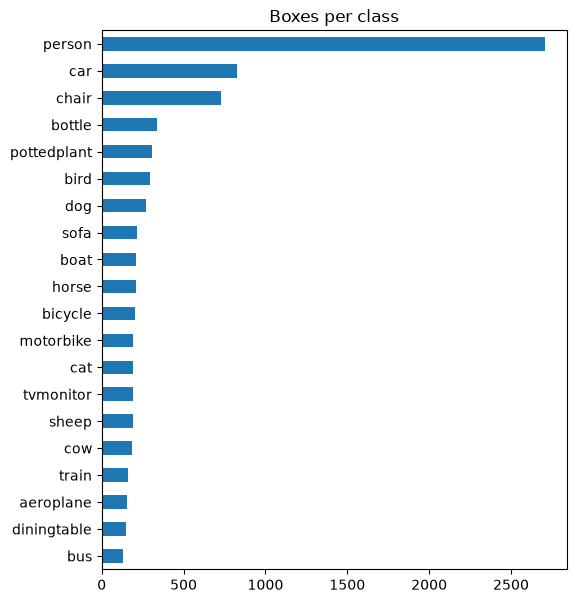

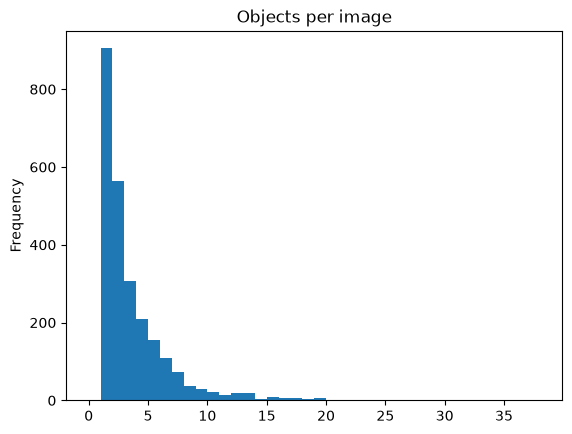

count    2501.000000
mean        3.136345
std         3.092604
min         1.000000
25%         1.000000
50%         2.000000
75%         4.000000
max        37.000000
dtype: float64
w    h  
500  375    1065
     333     325
375  500     195
500  332      71
333  500      70
Name: count, dtype: int64


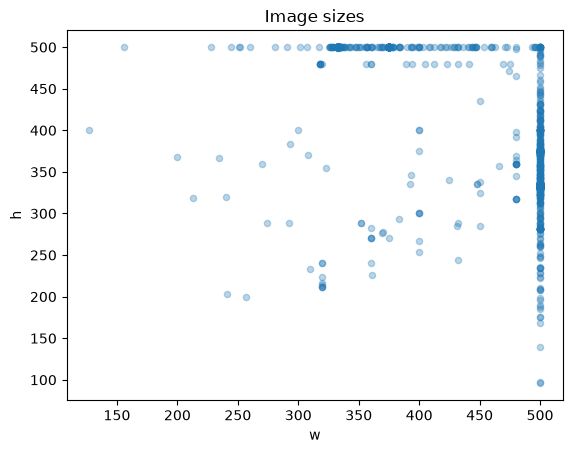

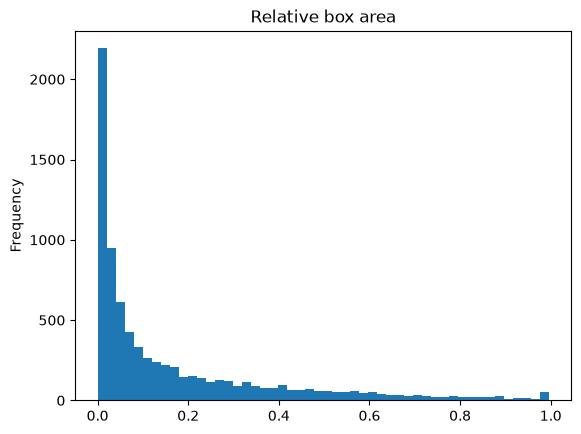

count    7844.000000
mean        0.168309
std         0.219359
min         0.000256
25%         0.016813
50%         0.067598
75%         0.238580
max         0.995339
dtype: float64
small (<1%): 0.17376338602753696


In [1]:
import fiftyone as fo
import fiftyone.zoo as foz
from fiftyone import ViewField as F
import pandas as pd
import matplotlib.pyplot as plt

dataset = foz.load_zoo_dataset("voc-2007", split="train")  
dataset.compute_metadata()  

print(dataset)                        
print(dataset.first())                 
print("images:", len(dataset))
print("boxes:", dataset.count("ground_truth.detections"))

counts = pd.Series(dataset.count_values("ground_truth.detections.label")).sort_values()
counts.plot.barh(figsize=(6, 7), title="Boxes per class")
plt.show()

per_img = pd.Series(dataset.values(F("ground_truth.detections").length()))
per_img.plot.hist(bins=range(0, per_img.max() + 2), title="Objects per image")
plt.show()
print(per_img.describe())

sizes = pd.DataFrame({
    "w": dataset.values("metadata.width"),
    "h": dataset.values("metadata.height"),
})
print(sizes.value_counts().head())     
sizes.plot.scatter(x="w", y="h", alpha=0.3, title="Image sizes")
plt.show()

boxes = dataset.values("ground_truth.detections.bounding_box")
areas = pd.Series([b[2] * b[3] for img in boxes for b in img])
areas.plot.hist(bins=50, title="Relative box area")
plt.show()
print(areas.describe())
print("small (<1%):", (areas < 0.01).mean())

session = fo.launch_app(dataset)

In [ ]:
import fiftyone as fo
import fiftyone.zoo as foz
from fiftyone import ViewField as F
import pandas as pd
import matplotlib.pyplot as plt

dataset = foz.load_zoo_dataset("voc-2012", split="train")  
dataset.compute_metadata()  

print(dataset)                        
print(dataset.first())                 
print("images:", len(dataset))
print("boxes:", dataset.count("ground_truth.detections"))

counts = pd.Series(dataset.count_values("ground_truth.detections.label")).sort_values()
counts.plot.barh(figsize=(6, 7), title="Boxes per class")
plt.show()

per_img = pd.Series(dataset.values(F("ground_truth.detections").length()))
per_img.plot.hist(bins=range(0, per_img.max() + 2), title="Objects per image")
plt.show()
print(per_img.describe())

sizes = pd.DataFrame({
    "w": dataset.values("metadata.width"),
    "h": dataset.values("metadata.height"),
})
print(sizes.value_counts().head())     
sizes.plot.scatter(x="w", y="h", alpha=0.3, title="Image sizes")
plt.show()

boxes = dataset.values("ground_truth.detections.bounding_box")
areas = pd.Series([b[2] * b[3] for img in boxes for b in img])
areas.plot.hist(bins=50, title="Relative box area")
plt.show()
print(areas.describe())
print("small (<1%):", (areas < 0.01).mean())

session = fo.launch_app(dataset)